<a href="https://colab.research.google.com/github/ramadasusiri2806-boop/flipkart_webscrapping_EDA/blob/main/Next_Word_Prediction_LSTM_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Next Word Prediction Using LSTM

This project uses Natural Language Processing and a Long Short-Term Memory (LSTM) neural network to predict the next word in a sequence.

**Topics covered:** text preprocessing, tokenization, sequence generation, padding, word embeddings, LSTM, model training, evaluation, accuracy/loss plots, and next-word prediction.

In [ ]:
import numpy as np
import re
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.utils import to_categorical
from sklearn.model_selection import train_test_split

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.20.0


## 1. Data Collection

A small text corpus is included so that the notebook can run directly in Google Colab without downloading a separate file. For a final submission, this corpus can be replaced with a larger public text dataset.

In [ ]:
text = """machine learning is a powerful technology
machine learning helps computers learn from data
deep learning is a part of machine learning
deep learning uses neural networks
neural networks are inspired by the human brain
natural language processing helps computers understand human language
natural language processing is used in chatbots
chatbots can understand and generate human language
artificial intelligence is changing the world
artificial intelligence can solve complex problems
data science uses statistics programming and machine learning
data science helps organizations make better decisions
python is a popular programming language
python is widely used in data science
python is also used in machine learning
machine learning models learn patterns from data
models can make predictions using learned patterns
deep learning models can process large amounts of data
lstm is useful for sequence prediction
lstm can remember important information from previous words
lstm networks are useful in natural language processing
text prediction is an important application of natural language processing
next word prediction can improve typing assistance
next word prediction is used in smart keyboards
language models predict the probability of words
language models can generate meaningful sentences
artificial intelligence and machine learning are important technologies
machine learning and deep learning are widely used today
data is important for building machine learning models
good data can improve model performance"""

print(len(text))

1527


## 2. Data Preprocessing

The text is converted to lowercase and unwanted characters and extra spaces are removed.

In [ ]:
import re

# Fix newline characters
text = text.replace("\\n", " ")

# Convert to lowercase
text = text.lower()

# Remove unwanted characters
text = re.sub(r'[^a-zA-Z\s]', ' ', text)

# Replace multiple spaces with one space
text = re.sub(r'\s+', ' ', text).strip()

print("Number of words:", len(text.split()))
print(text[:200])

Number of words: 217
machine learning is a powerful technology machine learning helps computers learn from data deep learning is a part of machine learning deep learning uses neural networks neural networks are inspired b


## 3. Tokenization

In [ ]:
tokenizer = Tokenizer()
tokenizer.fit_on_texts([text])

total_words = len(tokenizer.word_index) + 1

print("Total vocabulary size:", total_words)
print("Word index:", tokenizer.word_index)

Total vocabulary size: 90
Word index: {'learning': 1, 'is': 2, 'machine': 3, 'language': 4, 'data': 5, 'can': 6, 'models': 7, 'used': 8, 'in': 9, 'deep': 10, 'of': 11, 'are': 12, 'natural': 13, 'processing': 14, 'and': 15, 'prediction': 16, 'important': 17, 'a': 18, 'helps': 19, 'from': 20, 'networks': 21, 'the': 22, 'human': 23, 'artificial': 24, 'intelligence': 25, 'science': 26, 'python': 27, 'lstm': 28, 'computers': 29, 'learn': 30, 'uses': 31, 'neural': 32, 'understand': 33, 'chatbots': 34, 'generate': 35, 'programming': 36, 'make': 37, 'widely': 38, 'patterns': 39, 'useful': 40, 'for': 41, 'words': 42, 'next': 43, 'word': 44, 'improve': 45, 'powerful': 46, 'technology': 47, 'part': 48, 'inspired': 49, 'by': 50, 'brain': 51, 'changing': 52, 'world': 53, 'solve': 54, 'complex': 55, 'problems': 56, 'statistics': 57, 'organizations': 58, 'better': 59, 'decisions': 60, 'popular': 61, 'also': 62, 'predictions': 63, 'using': 64, 'learned': 65, 'process': 66, 'large': 67, 'amounts': 68, 

## 4. Sequence Generation

Each sequence contains previous words followed by the target next word.

In [ ]:
words = text.split()

input_sequences = []

for i in range(1, len(words)):
    sequence = tokenizer.texts_to_sequences(
        [' '.join(words[:i+1])]
    )[0]

    input_sequences.append(sequence)

print("Number of sequences:", len(input_sequences))
print("Sample sequences:", input_sequences[:5])

Number of sequences: 216
Sample sequences: [[3, 1], [3, 1, 2], [3, 1, 2, 18], [3, 1, 2, 18, 46], [3, 1, 2, 18, 46, 47]]


## 5. Padding Sequences

In [ ]:
from tensorflow.keras.preprocessing.sequence import pad_sequences
import numpy as np

max_sequence_len = max(
    len(sequence) for sequence in input_sequences
)

input_sequences = np.array(
    pad_sequences(
        input_sequences,
        maxlen=max_sequence_len,
        padding='pre'
    )
)

print("Maximum sequence length:", max_sequence_len)
print("Input shape:", input_sequences.shape)

Maximum sequence length: 217
Input shape: (216, 217)


## 6. Prepare Training and Validation Data

In [ ]:
X = input_sequences[:, :-1]
y = input_sequences[:, -1]

y = to_categorical(y, num_classes=total_words)

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))

Training samples: 172
Validation samples: 44


## 7. Build the LSTM Model

Architecture:

Input → Embedding → LSTM → Dropout → Dense/Softmax → Next Word

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense, Dropout

model = Sequential([
    Input(shape=(max_sequence_len - 1,)),
    Embedding(
        input_dim=total_words,
        output_dim=100
    ),
    LSTM(150),
    Dropout(0.2),
    Dense(total_words, activation='softmax')
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 216, 100)       │         9,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 150)            │       150,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 150)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 90)             │        13,590 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 173,190 (676.52 KB)

 Trainable params: 173,190 (676.52 KB)

 Non-trainable params: 0 (0.00 B)

## 8. Compile the Model

In [ ]:
model.compile(
    loss='categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

print("Model compiled successfully.")

Model compiled successfully.


## 9. Train the Model

In [ ]:
history = model.fit(
    X_train,
    y_train,
    epochs=100,
    validation_data=(X_val, y_val),
    verbose=1
)

Epoch 1/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 5s 487ms/step - accuracy: 0.0349 - loss: 4.4970 - val_accuracy: 0.0227 - val_loss: 4.4968
Epoch 2/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 4s 623ms/step - accuracy: 0.0581 - loss: 4.4656 - val_accuracy: 0.0227 - val_loss: 4.4980
Epoch 3/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 5s 781ms/step - accuracy: 0.0581 - loss: 4.2752 - val_accuracy: 0.0227 - val_loss: 4.8183
Epoch 4/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 493ms/step - accuracy: 0.0640 - loss: 4.2372 - val_accuracy: 0.0227 - val_loss: 4.7734
Epoch 5/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 464ms/step - accuracy: 0.0814 - loss: 4.1348 - val_accuracy: 0.0227 - val_loss: 4.7520
Epoch 6/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 433ms/step - accuracy: 0.0814 - loss: 4.1061 - val_accuracy: 0.0227 - val_loss: 4.8311
Epoch 7/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 4s 354ms/step - accuracy: 0.0872 - loss: 4.0651 - val_accuracy: 0.0227 - val_loss: 4.9134
Epoch 8/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 342ms/step - accuracy: 0.0930 - loss: 4.0527 - val_accuracy: 0.0227 - v

## 10. Training and Validation Accuracy

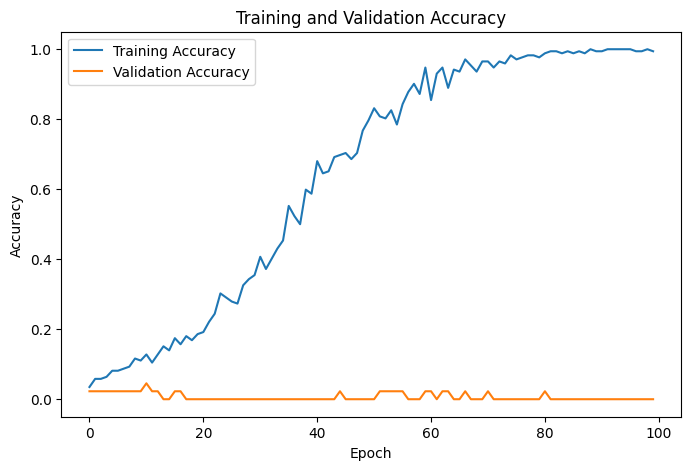

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy')
plt.legend()
plt.show()

## 11. Training and Validation Loss

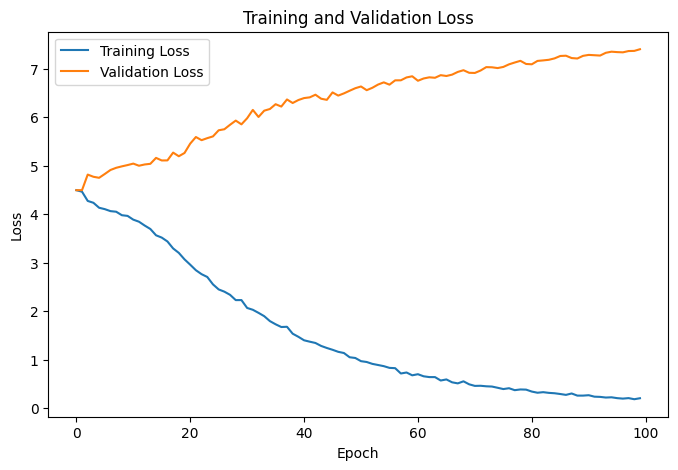

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()
plt.show()

## 12. Model Evaluation

In [ ]:
loss, accuracy = model.evaluate(X_val, y_val, verbose=0)

print("Validation Loss:", loss)
print("Validation Accuracy:", accuracy)

Validation Loss: 7.402565002441406
Validation Accuracy: 0.0


## 13. Next Word Prediction Function

In [ ]:
def predict_next_word(seed_text):
    token_list = tokenizer.texts_to_sequences([seed_text.lower()])[0]

    token_list = pad_sequences(
        [token_list],
        maxlen=max_sequence_len - 1,
        padding='pre'
    )

    predicted = model.predict(token_list, verbose=0)
    predicted_word_index = np.argmax(predicted, axis=1)[0]

    for word, index in tokenizer.word_index.items():
        if index == predicted_word_index:
            return word

    return None

## 14. Test Next Word Prediction

In [ ]:
test_sentences = [
    "machine learning is",
    "deep learning is",
    "natural language",
    "artificial intelligence",
    "data science",
    "python is",
    "lstm is"
]

for sentence in test_sentences:
    prediction = predict_next_word(sentence)
    print(f"Input: {sentence} -> Predicted next word: {prediction}")

Input: machine learning is -> Predicted next word: a
Input: deep learning is -> Predicted next word: a
Input: natural language -> Predicted next word: is
Input: artificial intelligence -> Predicted next word: is
Input: data science -> Predicted next word: is
Input: python is -> Predicted next word: a
Input: lstm is -> Predicted next word: a


## 15. Generate Multiple Words

In [ ]:
def generate_text(seed_text, next_words):
    for _ in range(next_words):
        next_word = predict_next_word(seed_text)

        if next_word is None:
            break

        seed_text += " " + next_word

    return seed_text

result = generate_text("machine learning", 5)

print("Generated Text:")
print(result)

Generated Text:
machine learning is a powerful technology machine


## 16. Project Summary

This project developed a Next Word Prediction system using an LSTM neural network. The text corpus was cleaned, tokenized, converted into sequences, padded, and used to train an LSTM model. An embedding layer represented words numerically, while the LSTM learned sequential relationships. The model was evaluated using accuracy and loss, and a prediction function was developed to predict the next word from an input sequence.

## Conclusion

The project demonstrates the use of NLP and Deep Learning for sequence prediction. The model can be extended to smart keyboards, autocomplete systems, chatbots, and text generation applications.